In [6]:
import sys
sys.path.append('/home/HwHiAiUser/pyadi-iio/')
sys.path.append('/home/HwHiAiUser/libiio')
import adi
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

In [7]:
# Create radio
sdr = adi.ad9363("ip:192.168.2.1")

sample_rate = 20e6 # Hz
center_freq = 2.0e9 # Hz

sdr.tx_enabled_channels = [0, 1]
sdr.gain_control_mode_chan0 = "manual"
sdr.gain_control_mode_chan1 = "manual"
sdr.tx_hardwaregain_chan0 = int(0)
sdr.tx_hardwaregain_chan1 = int(0)
sdr.tx_rf_bandwidth = int(sample_rate)
sdr.sample_rate = int(sample_rate)
sdr.tx_lo = int(center_freq)
sdr.tx_cyclic_buffer = True

In [8]:
# === FFT CONFIGURATION ===
N = sdr.rx_buffer_size
fs = sdr.sample_rate
freqs = np.fft.fftfreq(N, 1/fs)
freqs = np.fft.fftshift(freqs)

(-10.0, 9.98046875)

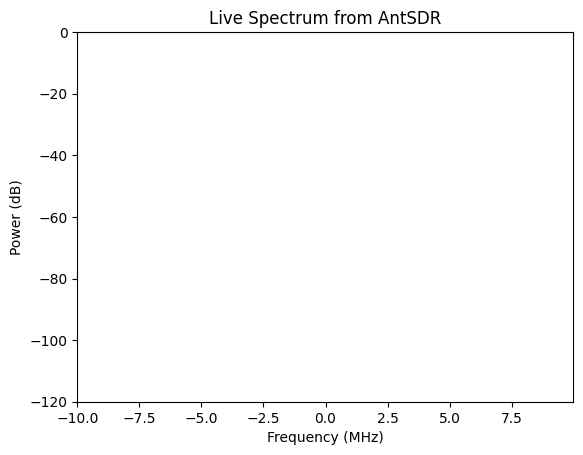

In [9]:
# === MATPLOTLIB SETUP ===
fig, ax = plt.subplots()
line, = ax.plot(freqs/1e6, np.zeros(N))
ax.set_title("Live Spectrum from AntSDR")
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Power (dB)")
ax.set_ylim(-120, 0)
ax.set_xlim(freqs[0]/1e6, freqs[-1]/1e6)

In [10]:
# === UPDATE FUNCTION ===
def update(frame):
    samples = sdr.rx()[0]  # complex64 array
    fft_data = np.fft.fftshift(np.fft.fft(samples))
    psd = 20 * np.log10(np.abs(fft_data) + 1e-8)
    line.set_ydata(psd - np.max(psd))  # normalize
    return (line,)

In [12]:
ani = animation.FuncAnimation(fig, update, interval=100, blit=True)
plt.show()

/tmp/ipykernel_10803/2567103101.py:1: UserWarning: frames=None which we can infer the length of, did not pass an explicit *save_count* and passed cache_frame_data=True.  To avoid a possibly unbounded cache, frame data caching has been disabled. To suppress this warning either pass `cache_frame_data=False` or `save_count=MAX_FRAMES`.
  ani = animation.FuncAnimation(fig, update, interval=100, blit=True)
